# Bài tập thêm - Bài 2 (Trang 32): Tính F-measure của các bài tập cơ bản
**Trần Minh Tấn - 6451071071**

Công thức: **F-measure = 2 × (precision × recall) / (precision + recall)**

## Cell 1: Cài đặt, kết nối dữ liệu và hàm tính F-measure

In [1]:
!pip install -q gdown

import gdown, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score

HO_TEN = "Trần Minh Tấn"
MSSV   = "6451071071"

def info(cau=""):
    print("=" * 60)
    print(f"Họ tên : {HO_TEN}")
    print(f"MSSV   : {MSSV}")
    if cau:
        print(f"Nội dung: {cau}")
    print("=" * 60)

info("Cài đặt, kết nối dữ liệu và hàm tính F-measure")

# ---- ID các file trên Drive
IDS = {
    "adult_data.csv": "1BYKP73pyzphA5YHR1fVvn2A0kBpr09TB",
    "adult_test.csv": "1Vh7e1IBL0SRxjT3gU_v_rnIcAT18griD",
    "winequality-red.csv": "1rzLiUi64RLmMV8ApudCt6aJyv_OkhADH",
    "heart.csv": "10N9jGzMn-MagDWXORdP-qIpwC3omZJHb",
    "mushrooms.csv": "11OXFpnwUwK_Ka9BFmboMoT9RhTRe3CFW",
}
for ten_file, id_file in IDS.items():
    gdown.download(id=id_file, output=ten_file, quiet=True)
print("Đã tải xong", len(IDS), "file dữ liệu")

# ---- Công thức F-measure
def f_measure(precision, recall):
    """F-measure = 2 * precision * recall / (precision + recall)"""
    precision, recall = np.asarray(precision, float), np.asarray(recall, float)
    tu, mau = 2 * precision * recall, precision + recall
    return np.divide(tu, mau, out=np.zeros_like(tu), where=mau > 0)

def tinh_f_measure(y_true, y_pred, pos_label=None):
    """Tính precision, recall, F-measure từ ma trận nhầm lẫn.
    - Bài toán 2 lớp: tính cho lớp dương pos_label.
    - Bài toán nhiều lớp: trung bình có trọng số theo số mẫu mỗi lớp (weighted)."""
    labels = sorted(set(y_true) | set(y_pred))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    TP = np.diag(cm).astype(float)
    FP = cm.sum(axis=0) - TP
    FN = cm.sum(axis=1) - TP
    P = np.divide(TP, TP + FP, out=np.zeros(len(labels)), where=(TP + FP) > 0)
    R = np.divide(TP, TP + FN, out=np.zeros(len(labels)), where=(TP + FN) > 0)
    F = f_measure(P, R)
    if pos_label is not None:
        i = labels.index(pos_label)
        return P[i], R[i], F[i]
    w = cm.sum(axis=1) / cm.sum()
    return (P * w).sum(), (R * w).sum(), (F * w).sum()

ket_qua = []   # bảng tổng hợp

def danh_gia(bai, mo_hinh, y_true, y_pred, pos_label=None):
    P, R, F = tinh_f_measure(y_true, y_pred, pos_label)
    # kiểm tra lại bằng thư viện sklearn
    F_sk = f1_score(y_true, y_pred, pos_label=pos_label, zero_division=0) if pos_label is not None \
           else f1_score(y_true, y_pred, average="weighted", zero_division=0)
    ket_qua.append({"Bài": bai, "Mô hình": mo_hinh,
                    "Accuracy": accuracy_score(y_true, y_pred),
                    "Precision": P, "Recall": R,
                    "F-measure": F, "F1 (sklearn)": F_sk})
    print(f"{bai} - {mo_hinh}: Precision={P:.4f}  Recall={R:.4f}  F-measure={F:.4f}  (sklearn: {F_sk:.4f})")

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Cài đặt, kết nối dữ liệu và hàm tính F-measure
Đã tải xong 5 file dữ liệu


## Cell 2: Ví dụ minh họa công thức

In [2]:
info("Ví dụ minh họa công thức F-measure")

# Giả sử mô hình có: TP = 40, FP = 10, FN = 20
TP, FP, FN = 40, 10, 20
precision = TP / (TP + FP)
recall    = TP / (TP + FN)
F = 2 * precision * recall / (precision + recall)

print(f"Precision = TP/(TP+FP) = {TP}/{TP+FP} = {precision:.4f}")
print(f"Recall    = TP/(TP+FN) = {TP}/{TP+FN} = {recall:.4f}")
print(f"F-measure = 2*P*R/(P+R) = {F:.4f}")

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Ví dụ minh họa công thức F-measure
Precision = TP/(TP+FP) = 40/50 = 0.8000
Recall    = TP/(TP+FN) = 40/60 = 0.6667
F-measure = 2*P*R/(P+R) = 0.7273


## Cell 3: Bài 2 - Adult Income (ID3, CART, Naive Bayes)

In [3]:
info("Bài Adult Income - tính F-measure (lớp dương: >50K)")

from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

cols = ["age","workclass","fnlwgt","education","education-num","marital-status",
        "occupation","relationship","race","sex","capital-gain","capital-loss",
        "hours-per-week","native-country","income"]

def doc_file(path):
    with open(path, encoding="utf-8-sig") as f:
        lines = f.readlines()
    skip = 1 if lines[0].lstrip().startswith("|") else 0
    has_header = lines[skip].split(",")[0].strip().lower() == "age"
    d = pd.read_csv(path, skiprows=skip, header=0 if has_header else None, skipinitialspace=True)
    d.columns = cols if d.shape[1] == 15 else [c for c in cols if c != "fnlwgt"]
    d["income"] = d["income"].astype(str).str.strip().str.rstrip(".")
    return d

tr, te = doc_file("adult_data.csv"), doc_file("adult_test.csv")
tr["_set"], te["_set"] = "train", "test"
tr = tr.replace("?", np.nan).dropna().drop(columns=["fnlwgt"], errors="ignore")
te = te.replace("?", np.nan).dropna().drop(columns=["fnlwgt"], errors="ignore")
d = pd.concat([tr, te], ignore_index=True)

X, y = d.drop(columns="income"), d["income"]
X = pd.get_dummies(X, columns=X.select_dtypes("object").columns.drop("_set"), dtype=int)
m = X["_set"] == "train"
X_train, X_test = X[m].drop(columns="_set"), X[~m].drop(columns="_set")
y_train, y_test = y[m], y[~m]

for ten, mh in [("ID3",  DecisionTreeClassifier(criterion="entropy", max_depth=5, random_state=42)),
                ("CART", DecisionTreeClassifier(criterion="gini",    max_depth=5, random_state=42)),
                ("Naive Bayes", GaussianNB())]:
    mh.fit(X_train, y_train)
    danh_gia("Adult Income", ten, y_test, mh.predict(X_test), pos_label=">50K")

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Bài Adult Income - tính F-measure (lớp dương: >50K)
Adult Income - ID3: Precision=0.7809  Recall=0.4895  F-measure=0.6018  (sklearn: 0.6018)
Adult Income - CART: Precision=0.7781  Recall=0.4919  F-measure=0.6027  (sklearn: 0.6027)
Adult Income - Naive Bayes: Precision=0.5690  Recall=0.8159  F-measure=0.6704  (sklearn: 0.6704)


## Cell 4: Bài 4 - Red Wine Quality (ID3, CART, Naive Bayes)

In [4]:
info("Bài Red Wine Quality - tính F-measure (nhiều lớp, trung bình có trọng số)")

from sklearn.model_selection import train_test_split

wine = pd.read_csv("winequality-red.csv")
X, y = wine.drop(columns="quality"), wine["quality"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

for ten, mh in [("ID3",  DecisionTreeClassifier(criterion="entropy", max_depth=5, random_state=42)),
                ("CART", DecisionTreeClassifier(criterion="gini",    max_depth=5, random_state=42)),
                ("Naive Bayes", GaussianNB())]:
    mh.fit(X_train, y_train)
    danh_gia("Red Wine Quality", ten, y_test, mh.predict(X_test))

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Bài Red Wine Quality - tính F-measure (nhiều lớp, trung bình có trọng số)
Red Wine Quality - ID3: Precision=0.5603  Recall=0.5792  F-measure=0.5594  (sklearn: 0.5594)
Red Wine Quality - CART: Precision=0.5353  Recall=0.5687  F-measure=0.5485  (sklearn: 0.5485)
Red Wine Quality - Naive Bayes: Precision=0.5471  Recall=0.5417  F-measure=0.5433  (sklearn: 0.5433)


## Cell 5: Bài 5 - Heart Disease (ID3, CART, Naive Bayes)

In [5]:
info("Bài Heart Disease - tính F-measure (lớp dương: 1 = có bệnh)")

heart = pd.read_csv("heart.csv", encoding="utf-8-sig").dropna().reset_index(drop=True)
X, y = heart.drop(columns="target"), heart["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

for ten, mh in [("ID3",  DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42)),
                ("CART", DecisionTreeClassifier(criterion="gini",    max_depth=4, random_state=42)),
                ("Naive Bayes", GaussianNB())]:
    mh.fit(X_train, y_train)
    danh_gia("Heart Disease", ten, y_test, mh.predict(X_test), pos_label=1)

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Bài Heart Disease - tính F-measure (lớp dương: 1 = có bệnh)
Heart Disease - ID3: Precision=0.8205  Recall=0.6400  F-measure=0.7191  (sklearn: 0.7191)
Heart Disease - CART: Precision=0.8205  Recall=0.6400  F-measure=0.7191  (sklearn: 0.7191)
Heart Disease - Naive Bayes: Precision=0.8889  Recall=0.8000  F-measure=0.8421  (sklearn: 0.8421)


## Cell 6: Bài 6 - Mushroom (ID3, CART, Naive Bayes)

In [6]:
info("Bài Mushroom - tính F-measure (lớp dương: p = nấm độc)")

from sklearn.naive_bayes import BernoulliNB

nam = pd.read_csv("mushrooms.csv")
X, y = nam.drop(columns="class"), nam["class"]
X = pd.get_dummies(X, dtype=int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

for ten, mh in [("ID3",  DecisionTreeClassifier(criterion="entropy", random_state=42)),
                ("CART", DecisionTreeClassifier(criterion="gini",    random_state=42)),
                ("Naive Bayes", BernoulliNB())]:
    mh.fit(X_train, y_train)
    danh_gia("Mushroom", ten, y_test, mh.predict(X_test), pos_label="p")

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Bài Mushroom - tính F-measure (lớp dương: p = nấm độc)
Mushroom - ID3: Precision=1.0000  Recall=1.0000  F-measure=1.0000  (sklearn: 1.0000)
Mushroom - CART: Precision=1.0000  Recall=1.0000  F-measure=1.0000  (sklearn: 1.0000)
Mushroom - Naive Bayes: Precision=0.9848  Recall=0.8781  F-measure=0.9284  (sklearn: 0.9284)


## Cell 7: Bài 7 - Nhận dạng chữ số viết tay (ID3)

In [7]:
info("Bài nhận dạng chữ số viết tay - tính F-measure (nhiều lớp, trung bình có trọng số)")

from sklearn import datasets, tree

digits = datasets.load_digits()
data = digits.images.reshape((len(digits.images), -1))
X_train, X_test, y_train, y_test = train_test_split(data, digits.target, test_size=0.2, shuffle=False)

classifier = tree.DecisionTreeClassifier(criterion="entropy", random_state=33)
classifier.fit(X_train, y_train)
danh_gia("Chữ số viết tay", "ID3", y_test, classifier.predict(X_test))

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Bài nhận dạng chữ số viết tay - tính F-measure (nhiều lớp, trung bình có trọng số)
Chữ số viết tay - ID3: Precision=0.7953  Recall=0.7972  F-measure=0.7947  (sklearn: 0.7947)


## Cell 8: Bảng tổng hợp F-measure của các bài tập cơ bản

Họ tên : Trần Minh Tấn
MSSV   : 6451071071
Nội dung: Bảng tổng hợp F-measure của các bài tập cơ bản


,Bài,Mô hình,Accuracy,Precision,Recall,F-measure,F1 (sklearn)
0,Adult Income,ID3,0.8408,0.7809,0.4895,0.6018,0.6018
1,Adult Income,CART,0.8407,0.7781,0.4919,0.6027,0.6027
2,Adult Income,Naive Bayes,0.8029,0.5690,0.8159,0.6704,0.6704
3,Red Wine Quality,ID3,0.5792,0.5603,0.5792,0.5594,0.5594
4,Red Wine Quality,CART,0.5688,0.5353,0.5688,0.5485,0.5485
5,Red Wine Quality,Naive Bayes,0.5417,0.5471,0.5417,0.5433,0.5433
6,Heart Disease,ID3,0.7253,0.8205,0.6400,0.7191,0.7191
7,Heart Disease,CART,0.7253,0.8205,0.6400,0.7191,0.7191
8,Heart Disease,Naive Bayes,0.8352,0.8889,0.8000,0.8421,0.8421
9,Mushroom,ID3,1.0000,1.0000,1.0000,1.0000,1.0000


Công thức tự cài đặt trùng với sklearn: True


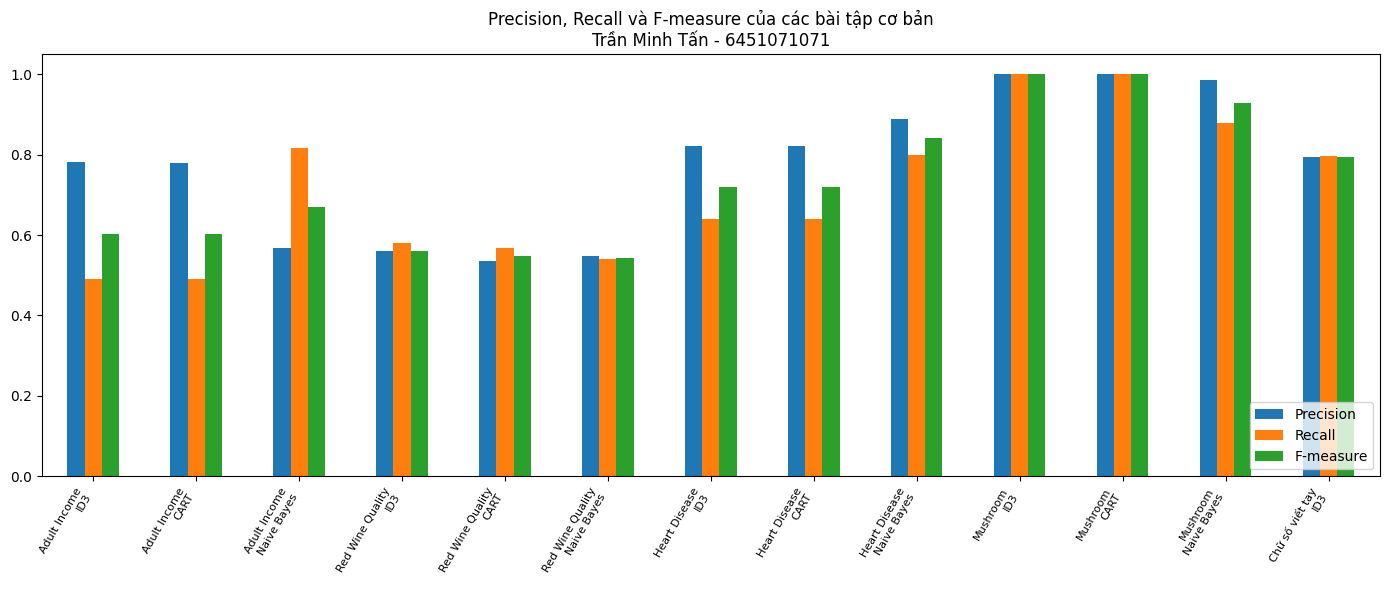

In [8]:
info("Bảng tổng hợp F-measure của các bài tập cơ bản")

bang = pd.DataFrame(ket_qua).round(4)
display(bang)

# Kiểm tra: công thức tự cài đặt trùng với sklearn
print("Công thức tự cài đặt trùng với sklearn:", np.allclose(bang["F-measure"], bang["F1 (sklearn)"], atol=1e-4))

# Biểu đồ
ve = bang.copy()
ve["Nhãn"] = ve["Bài"] + "\n" + ve["Mô hình"]
ve.plot(x="Nhãn", y=["Precision", "Recall", "F-measure"], kind="bar", figsize=(14,6), ylim=(0,1.05))
plt.title(f"Precision, Recall và F-measure của các bài tập cơ bản\n{HO_TEN} - {MSSV}")
plt.xlabel(""); plt.xticks(rotation=60, ha="right", fontsize=8)
plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

# Xuất file Excel (tùy chọn)
bang.to_excel("F_measure_tong_hop.xlsx", index=False)